# 03 · Rysunki – emocje (H1–H3)

## 1. Konfiguracja

In [1]:
import sys
sys.path.append("..")

import matplotlib.pyplot as plt
import pandas as pd

from src.config import (APA_STYLE, CYCLES, FIGURES_DIR, PHASES, POLITICAL_SUBREDDITS, PROCESSED_DIR, RESULTS_DIR,
                        SUBREDDIT_STYLES)

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update(APA_STYLE)

## 2. Dane

In [2]:
weekly = pd.read_csv(PROCESSED_DIR / "weekly_emotions.csv", parse_dates=["week_start"])
h3 = pd.read_csv(RESULTS_DIR / "h3_phase_means.csv")

FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\karol\\Licencjat_programowanie\\Licencjat\\processed\\results\\h3_phase_means.csv'

## 3. Emocje negatywne i pobudzenie w czasie (H1, H2)

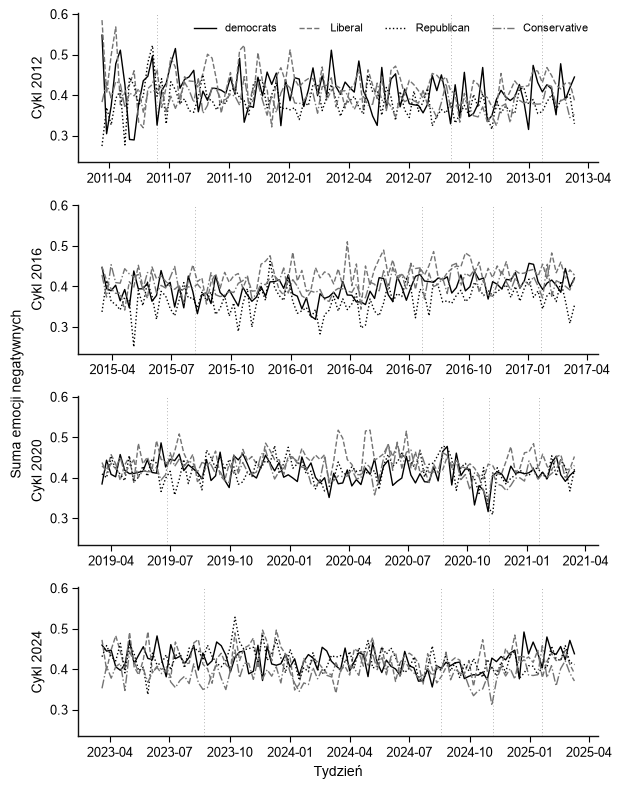

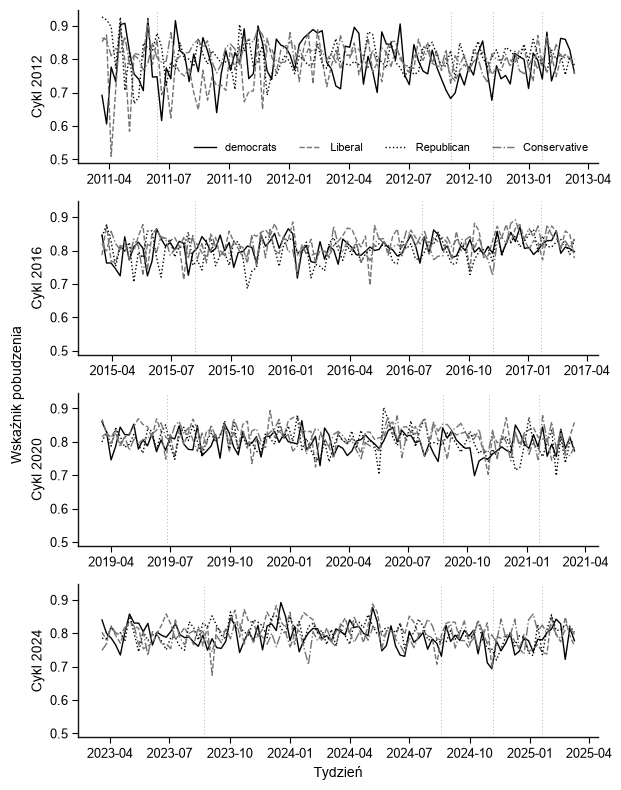

In [3]:
for variable, ylabel, name in (("negative", "Suma emocji negatywnych", "negative_weekly"), ("arousal", "Wskaźnik pobudzenia", "arousal_weekly")):
    fig, axes = plt.subplots(len(CYCLES), 1, figsize=(6.3, 8), sharey=True)
    for ax, cycle in zip(axes, CYCLES):
        for phase, start, end in PHASES[cycle][1:]:
            ax.axvline(pd.Timestamp(start), color="0.6", linewidth=0.6, linestyle=(0, (1, 3)))
        for subreddit in POLITICAL_SUBREDDITS:
            rows = weekly[(weekly["subreddit"] == subreddit) & (weekly["cycle"] == cycle)]
            color, linestyle = SUBREDDIT_STYLES[subreddit]
            ax.plot(rows["week_start"], rows[variable], color=color, linestyle=linestyle, linewidth=1, label=subreddit)
        ax.set_ylabel(f"Cykl {cycle}")
    axes[0].legend(ncol=4, frameon=False, fontsize=8)
    axes[-1].set_xlabel("Tydzień")
    fig.text(0.02, 0.5, ylabel, rotation=90, va="center")
    fig.tight_layout(rect=(0.03, 0, 1, 1))
    fig.savefig(FIGURES_DIR / f"{name}.png", dpi=300, bbox_inches="tight")
    plt.show()

## 4. Trzy fazy obok siebie (H3)

NameError: name 'h3' is not defined

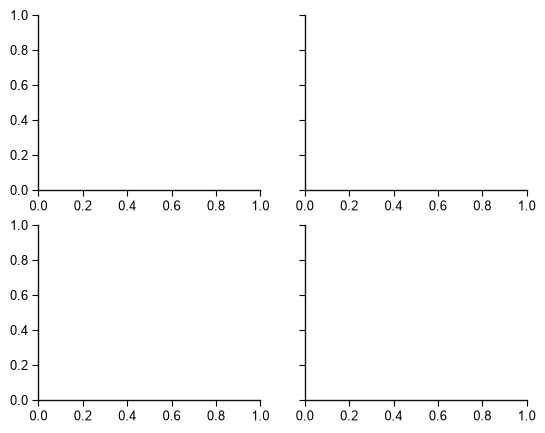

In [4]:
hatches = {"bazowa": "", "szczytowa": "///", "powyborcza": "..."}
fig, axes = plt.subplots(2, 2, figsize=(6.3, 5), sharey=True)
for ax, subreddit in zip(axes.ravel(), POLITICAL_SUBREDDITS):
    rows = h3[h3["subreddit"] == subreddit].set_index("cycle").loc[CYCLES]
    for position, (phase, hatch) in enumerate(hatches.items()):
        ax.bar([index + (position - 1) * 0.27 for index in range(len(CYCLES))], rows[phase], width=0.27, color="white",
               edgecolor="black", hatch=hatch, label=phase.capitalize())
    ax.set_xticks(range(len(CYCLES)), CYCLES)
    ax.set_title(subreddit, fontsize=10)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, frameon=False)
fig.supylabel("Suma emocji negatywnych")
fig.tight_layout(rect=(0, 0.06, 1, 1))
fig.savefig(FIGURES_DIR / "negative_phases.png", dpi=300, bbox_inches="tight")
plt.show()